In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep,
)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

In [2]:
df = pd.read_csv("dataset/marketing_AB_clean.csv")

In [3]:
# 1. Summary counts per group
ad = df[df["test_group"] == "ad"]["converted_int"]
psa = df[df["test_group"] == "psa"]["converted_int"]

In [4]:
n_ad, x_ad = len(ad), ad.sum()
n_psa, x_psa = len(psa), psa.sum()
p_ad, p_psa = x_ad / n_ad, x_psa / n_psa

In [5]:
print(f"Ad : n={n_ad:,}  conversions={x_ad:,}  rate={p_ad:.4%}")
print(f"PSA: n={n_psa:,}  conversions={x_psa:,}  rate={p_psa:.4%}")

Ad : n=564,577  conversions=14,423  rate=2.5547%
PSA: n=23,524  conversions=420  rate=1.7854%


In [6]:
# 2. Two-proportion z-test (one-sided: ad > psa)
z_stat, p_value = proportions_ztest(
    count=[x_ad, x_psa], nobs=[n_ad, n_psa], alternative="larger"
)
print(f"\nz-statistic: {z_stat:.3f}")
print(f"p-value    : {p_value:.3e}")
print("Reject H0 at 5%?", p_value < 0.05)


z-statistic: 7.370
p-value    : 8.526e-14
Reject H0 at 5%? True


In [7]:
# 3. Chi-square test as a cross-check (two-sided)
contingency = pd.crosstab(df["test_group"], df["converted"])
chi2, p_chi, dof, _ = stats.chi2_contingency(contingency)
print(f"\nChi-square: {chi2:.3f}, p-value: {p_chi:.3e}, dof: {dof}")
print(contingency)


Chi-square: 54.006, p-value: 1.999e-13, dof: 1
converted    False  True 
test_group               
ad          550154  14423
psa          23104    420


In [8]:
# 4. Lift and 95% confidence interval for the difference
abs_lift = p_ad - p_psa
rel_lift = abs_lift / p_psa
 
low, high = confint_proportions_2indep(
    x_ad, n_ad, x_psa, n_psa, method="wald", compare="diff", alpha=0.05
)
print(f"\nAbsolute lift : {abs_lift:.4%} (percentage points)")
print(f"Relative lift : {rel_lift:.2%}")
print(f"95% CI (diff) : [{low:.4%}, {high:.4%}]")


Absolute lift : 0.7692% (percentage points)
Relative lift : 43.09%
95% CI (diff) : [0.5951%, 0.9434%]


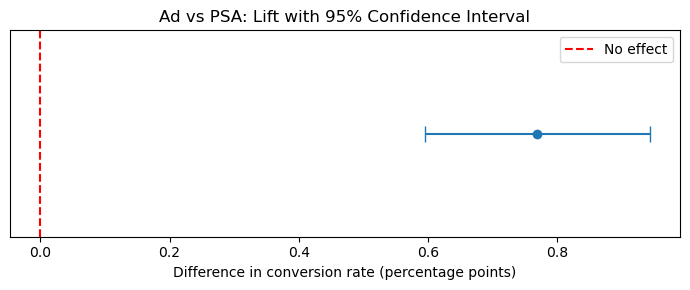

In [9]:
# 5. Visualise the confidence interval
plt.figure(figsize=(7, 3))
plt.errorbar(abs_lift * 100, 0, xerr=[[(abs_lift - low) * 100], [(high - abs_lift) * 100]],
             fmt="o", capsize=6, color="tab:blue")
plt.axvline(0, color="red", linestyle="--", label="No effect")
plt.yticks([])
plt.xlabel("Difference in conversion rate (percentage points)")
plt.title("Ad vs PSA: Lift with 95% Confidence Interval")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/lift_confidence_interval.png", dpi=150)
plt.show()

In [10]:
# 6. Power analysis: was the experiment big enough?
effect = proportion_effectsize(p_ad, p_psa)
analysis = NormalIndPower()

In [11]:
# Achieved power with the actual sample sizes
power = analysis.power(effect_size=effect, nobs1=n_psa, alpha=0.05,
                       ratio=n_ad / n_psa, alternative="larger")
print(f"\nAchieved power: {power:.3f}")


Achieved power: 1.000


In [12]:
# Minimum sample size per group to detect this effect (80% power, equal groups)
n_needed = analysis.solve_power(effect_size=effect, power=0.8, alpha=0.05,
                                ratio=1, alternative="larger")
print(f"Sample size per group needed (80% power, equal split): {int(np.ceil(n_needed)):,}")

Sample size per group needed (80% power, equal split): 4,402


In [13]:
# Minimum detectable effect (MDE) given the PSA group size
mde_effect = analysis.solve_power(nobs1=n_psa, power=0.8, alpha=0.05,
                                  ratio=n_ad / n_psa, alternative="larger")
print(f"Minimum detectable effect size (Cohen's h): {mde_effect:.4f}")

Minimum detectable effect size (Cohen's h): 0.0165


In [14]:
# %% 7. Rough business impact 
value_per_conversion = 50
cost_per_ad_user = 0.50

In [15]:
extra_conversions = abs_lift * n_ad
extra_revenue = extra_conversions * value_per_conversion
total_cost = cost_per_ad_user * n_ad
roi = (extra_revenue - total_cost) / total_cost

In [16]:
print(f"\nExtra conversions attributable to ad: {extra_conversions:,.0f}")
print(f"Incremental revenue: {extra_revenue:,.0f}")
print(f"Ad cost: {total_cost:,.0f}")
print(f"ROI: {roi:.1%}")


Extra conversions attributable to ad: 4,343
Incremental revenue: 217,149
Ad cost: 282,288
ROI: -23.1%
